### 💡 정규분포와 정규성 검정

정규분포(Normal Distribution)란 평균을 중심으로 좌우가 대칭인 종 모양의 확률 분포이다.

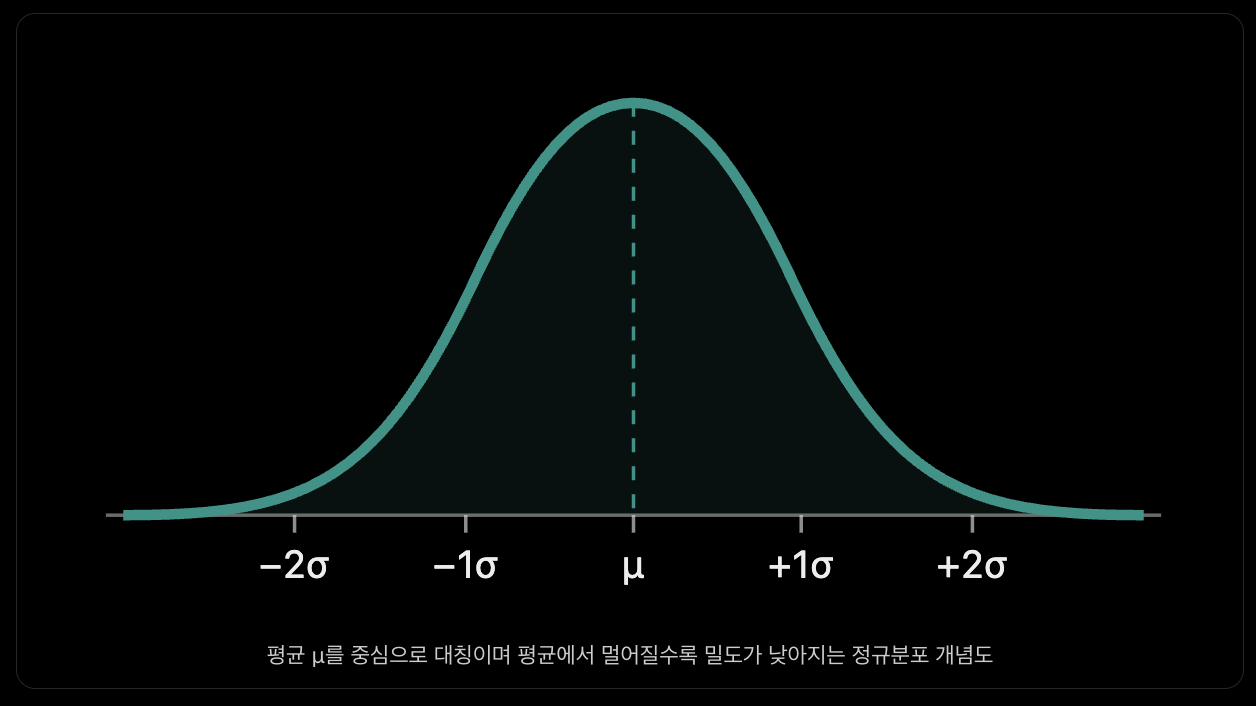

정규분포는 두가지 값으로 결정된다.
- 평균(μ): 분포의 중심
- 표준편차(σ): 분포가 얼마나 넓게 퍼져 있는지

내가 가진 데이터가 정규분포의 모양을 하고있는지 확인하는 과정을 정규성 검정이라고 한다.

여기서 단어를 좀 정리하자면
- **정규분포(Normal Distribution)** : 평균을 중심으로 좌우 대칭인 종 모양의 확률분포
- **정규성(Normality)** : 데이터가 정규분포를 따른다는 성질
- **정규성 확인** : 실제 데이터가 정규분포를 따른다고 볼만한지 확인하는 과정

정규성 확인은 데이터를 무조건 정규분포로 만드는 것이 아니다.

앞으로 사용하려는 분석 방법이 데이터에 적절한지 판단하기 위함이다.

예를들어 두 그룹의 평균이 서로 다른지 통계적으로 검정하려고 할 때, 일부 통계 검정은 정규분포와 관련된 가정을 사용하기 때문에

해당 가정을 하기 전에 데이터가 정규성을 띄는지 확인하는 것이다.

**정규성을 검정하는 방법으로는 크게 세가지가 있다.**

1. `히스토그램`
    - 해당 컬럼을 히스토그램으로 시각화를 해서 정규성을 띄는지 확인하는 것이다.

2. `Q-Q Plot`
    - 데이터의 분위수가 정규분포의 분위수와 비슷한지 확인하는 것이다.

3. `Shapiro-Wilk`
    - 정규분포 가정에 반대하는 통계적 증거가 있는지 확인하는 것이다.

아래 실습을 통해 하나하나씩 확인해보도록 하겠다. 사용할 컬럼은 아이리스 데이터셋에 `sepal_length`이다.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("./datasets/iris.csv")

print(df.head())
print("")
print("")
print(df.columns)
print("")
print("")
print(df.info())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB
None


In [ ]:
data = df["sepal_length"].dropna()

print("데이터 개수:", len(data))
print("평균:", data.mean())
print("표준편차:", data.std())
print("왜도:", data.skew())

데이터 개수: 150
평균: 5.843333333333334
표준편차: 0.828066127977863
왜도: 0.3149109566369728


### 1. 정규성 검정 - 히스토그램

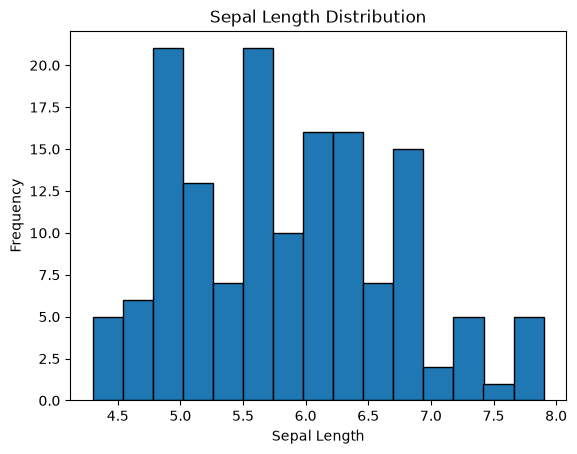

In [ ]:
plt.hist(data, bins=15, edgecolor="black")

plt.title("Sepal Length Distribution")
plt.xlabel("Sepal Length")
plt.ylabel("Frequency")

plt.show()

히스토그램에서는 다음과 같이 확인할 수 있다.
- 분포가 대략 정규성을 띄는가
- 특정 방향으로 긴 꼬리를 가지고 있는가

다만 히스토그램만으로는 구간에 따라서 모양이 달라지기 때문에 정규성을 확인할 수 없다.

### 2. 정규성 검정 - Q-Q Plot
Q-Q Plot(Quantile-Quantile Plot)은 실제 데이터의 분위수와 이론적인 정규분포의 분위수를 비교하는 그래프이다.

다시말하면, 실제 데이터가 정규분포를 따른다고 가정했을 때 기대되는 값들과 실제값이 얼마나 비슷한지를 확인하는 것이다.

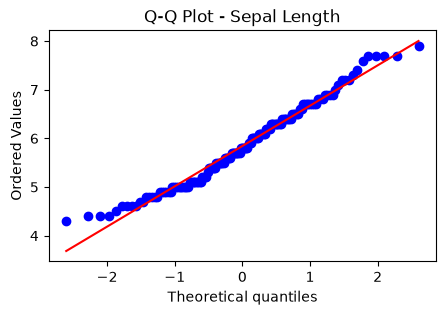

In [ ]:
plt.figure(figsize=(5,3))

# 아래 코드를 실행하면 대각선도 같이 나타난다.
# 대각선은 실제 데이터가 정규분포의 이론적 분위수와 얼마나 선형적인 관계를 갖는지 판단하는 기준이 된다.
stats.probplot(data, dist="norm", plot=plt)

plt.title("Q-Q Plot - Sepal Length")
plt.show()

위의 그래프를 해석해보자면

- X축 : Theoretical Quantiles (이론적 분위수)

    X축은 데이터가 표준정규분포를 따른다고 가정했을 때 기대되는 위치이다.

    예를들어 -2에있는 점들은 하위 약 2.3%에 위치, 0은 중앙값에 위치, 2는 하위 약 97.7%에 위치

- Y축 : Ordered Values (실제 정렬된 데이터 값)

    Y축은 실제 정렬된 데이터의 길이이다.

실제 점들이 기준 직선 근처에 있으면 정규분포와 비교적 잘 부합한다고 해석한다.

반대로 전들이 S자 모양으로 휘거나, 양 끝에서 크게 벗어나면 정규분포와 차이가 있을 가능성이 있다.

하지만, Q-Q Plot도 시각적 판단이므로, 세번째 방법인 Shapiro-Wilk방법을 함께 사용한다.

### 3. 정규성 검정 - Shapiro-Wilk

shapiro-wilk 검정은 데이터가 정규분포를 따른다는 가정과 관측된 데이터가 얼마나 잘 부합하는지 통계적으로 판단하는 방법이다.

#### 3-1. 가설설정

정규성 검정에는 두 가지 가설을 사용한다.
- 귀무가설(H₀): 데이터가 정규분포를 따르는 모집단에서 추출되었다.
- 대립가설(H₁): 데이터가 정규분포를 따르는 모집단에서 추출되지 않았다.

여기서 귀무가설은 통계적 검정을 시작할 때 기준으로 삼는 가설이다.

#### 3-2. 유의수준과 p-value

보통 `유의수준`(Significance Level)을 0.05로 설정한다.

`p-value`는 **귀무가설이 참이라는 가정하에서, 관측한 검정통계량만큼 또는 그보다 더 극단적인 결과가 나올 확률**이다.

| 검정 결과 | 판단 | 해석 |
| --- | --- | --- |
| p-value < 0.05 | 귀무가설 기각 | 정규분포 가정에 반하는 통계적 근거가 있음 |
| p-value ≥ 0.05 | 귀무가설 기각하지 않음 | 정규분포 가정에 반하는 증거가 충분하지 않음 |

In [ ]:
from scipy import stats

# 아래 코드는 두 개의 결과를 반환한다.
# statistic : 검정 통계량(= W 통계량) 
# > 일반적으로 0과 1을 가지먀 1에 가까울수록 정규분포와 잘 맞는다는 의미
# p_value = 귀무가설이 참이라고 가정했을때, 실제로 관측한 것만큼 또는 그보다 더 극단적인 검정 통계량이 나올 확률
statistic, p_value = stats.shapiro(data)

print("검정통계량:", statistic)
print("p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("귀무가설 기각: 정규성 가정에 반하는 증거가 있음")
else:
    print("귀무가설 기각하지 않음: 정규성을 부정할 증거가 충분하지 않음")

검정통계량: 0.9760902722402776
p-value: 0.010181161175628799
귀무가설 기각: 정규성 가정에 반하는 증거가 있음
